# Marketing channel ROI comparison

**Dataset:** [Digital Marketing Metrics and KPIs to Measure](https://www.kaggle.com/datasets/sinderpreet/analyze-the-marketing-spending) (sinderpreet, Kaggle)
**Period:** 1 to 28 February 2021 | 11 campaigns, 4 categories, 308 campaign days

Campaigns are the primary unit of analysis (11 groups, 55 pairs). Categories are a secondary
robustness check only, because they are unbalanced: social contains 6 campaigns, media contains 1.

Run top to bottom. Each part depends on the state the previous part built.

**Contents**
1. Dataset discovery, cleaning and marketing metrics
2. Pairwise comparisons (t tests, Fisher's exact) and effect sizes
3. Multiple comparisons correction (Bonferroni, Benjamini Hochberg)
4. Power analysis and sample size planning
5. Confidence intervals, composite ranking and budget allocation

Two deliberate deviations from the lab template, both defended in comments where they occur:
Welch t tests instead of Student's, and a measured coefficient of variation instead of a
hardcoded 0.15 in the power simulation.

Narrative conclusions are in `executive_memo.md`. The method critique is in `reflection.md`.
The standalone `.py` scripts reproduce these same five parts as separate command line stages.


In [1]:
# --- setup ----------------------------------------------------------------
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control

%matplotlib inline


def _project_root() -> Path:
    """Locate the lab folder whether run as a notebook or a script."""
    try:
        here = Path(__file__).resolve().parent
    except NameError:                      # running inside a notebook
        here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "data" / "marketing_raw.csv").exists():
            return cand
    return here


ROOT = _project_root()
DATA = ROOT / "data"
OUT = ROOT / "outputs"
FIG = ROOT / "figures"
for _d in (DATA, OUT, FIG):
    _d.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 220)
print(f"project root: {ROOT}")

project root: /home/claude/lab_statistical_analysis_gordan


---

## Part 1: dataset discovery, cleaning and marketing metrics

Load the Kaggle marketing panel, normalise campaign names, derive CPA, ROAS, CTR and conversion rate, then aggregate to campaign and category level.

In [2]:
RAW = DATA / "marketing_raw.csv"
CLEAN = DATA / "marketing_data.csv"

#### Load

In [3]:
# ---------------------------------------------------------------- load
df = pd.read_csv(RAW)
print("=" * 70)
print("RAW DATA")
print("=" * 70)
print(f"shape: {df.shape}")
print(f"columns: {list(df.columns)}")
print(df.dtypes)
print(df.head())
print("\nmissing values per column:")
print(df.isna().sum())

RAW DATA
shape: (308, 11)
columns: ['id', 'c_date', 'campaign_name', 'category', 'campaign_id', 'impressions', 'mark_spent', 'clicks', 'leads', 'orders', 'revenue']
id                 int64
c_date               str
campaign_name        str
category             str
campaign_id        int64
impressions        int64
mark_spent       float64
clicks             int64
leads              int64
orders             int64
revenue          float64
dtype: object
   id      c_date    campaign_name    category  campaign_id  impressions  mark_spent  clicks  leads  orders  revenue
0   1  2021-02-01   facebook_tier1      social       349043       148263     7307.37    1210     13       1   4981.0
1   2  2021-02-01   facebOOK_tier2      social       348934       220688    16300.20    1640     48       3  14962.0
2   3  2021-02-01       google_hot      search     89459845        22850     5221.60     457      9       1   7981.0
3   4  2021-02-01      google_wide      search       127823       147038     6

#### Clean

In [4]:
# ---------------------------------------------------------------- clean
# 1. campaign_name has inconsistent capitalisation ("facebOOK_tier2").
#    Left uncorrected this creates a phantom extra group.
before = df["campaign_name"].nunique()
df["campaign_name"] = df["campaign_name"].str.strip().str.lower()
after = df["campaign_name"].nunique()
print(f"\ncampaign_name distinct values: {before} raw -> {after} after case normalisation")

# 2. types
df["c_date"] = pd.to_datetime(df["c_date"])
num_cols = ["impressions", "mark_spent", "clicks", "leads", "orders", "revenue"]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# 3. structural checks
dupes = df.duplicated(subset=["c_date", "campaign_name"]).sum()
print(f"duplicate campaign/day rows: {dupes}")
print(f"negative values present: {(df[num_cols] < 0).any().any()}")
print(f"date range: {df.c_date.min().date()} to {df.c_date.max().date()} "
      f"({df.c_date.nunique()} distinct days)")

# 4. daily derived metrics.
#    Zero-order days give infinite CPA. We keep the rows (they are real,
#    informative days) and mark CPA as NaN so downstream tests can drop
#    them explicitly rather than silently.
df["ctr"] = df["clicks"] / df["impressions"]
df["lead_rate"] = df["leads"] / df["clicks"]
df["conv_rate"] = df["orders"] / df["clicks"]          # order per click
df["cpa"] = df["mark_spent"] / df["orders"]
df["roas"] = df["revenue"] / df["mark_spent"]
df["profit"] = df["revenue"] - df["mark_spent"]
df["aov"] = df["revenue"] / df["orders"]
df = df.replace([np.inf, -np.inf], np.nan)

zero_order_days = int((df["orders"] == 0).sum())
print(f"\nzero-order days (CPA undefined): {zero_order_days} of {len(df)} rows "
      f"({zero_order_days / len(df):.1%})")
print("zero-order days by campaign:")
print(df[df["orders"] == 0]["campaign_name"].value_counts())

df.to_csv(CLEAN, index=False)
print(f"\ncleaned panel saved to {CLEAN}")


campaign_name distinct values: 11 raw -> 11 after case normalisation
duplicate campaign/day rows: 0
negative values present: False
date range: 2021-02-01 to 2021-02-28 (28 distinct days)

zero-order days (CPA undefined): 19 of 308 rows (6.2%)
zero-order days by campaign:
campaign_name
instagram_tier2         3
facebook_retargeting    3
instagram_tier1         3
google_hot              3
facebook_tier2          2
facebook_lal            2
google_wide             2
banner_partner          1
Name: count, dtype: int64

cleaned panel saved to /home/claude/lab_statistical_analysis_gordan/data/marketing_data.csv


#### Aggregates

In [5]:
# ---------------------------------------------------------------- aggregates
def aggregate(frame: pd.DataFrame, key: str) -> pd.DataFrame:
    g = frame.groupby(key).agg(
        days=("c_date", "nunique"),
        impressions=("impressions", "sum"),
        clicks=("clicks", "sum"),
        leads=("leads", "sum"),
        orders=("orders", "sum"),
        spend=("mark_spent", "sum"),
        revenue=("revenue", "sum"),
    )
    g["CTR"] = g["clicks"] / g["impressions"]
    g["lead_rate"] = g["leads"] / g["clicks"]
    g["conv_rate"] = g["orders"] / g["clicks"]
    g["CPA"] = g["spend"] / g["orders"]
    g["ROAS"] = g["revenue"] / g["spend"]
    g["profit"] = g["revenue"] - g["spend"]
    g["profit_margin"] = g["profit"] / g["revenue"]
    g["AOV"] = g["revenue"] / g["orders"]
    return g.replace([np.inf, -np.inf], np.nan).sort_values("ROAS", ascending=False)

camp = aggregate(df, "campaign_name")
cat = aggregate(df, "category")

print("\n" + "=" * 70)
print("CAMPAIGN SUMMARY (primary grouping, 11 groups)")
print("=" * 70)
print(camp.round(3).to_string())

print("\n" + "=" * 70)
print("CATEGORY SUMMARY (secondary grouping, 4 groups)")
print("=" * 70)
print(cat.round(3).to_string())
print("\nNOTE: categories are unbalanced (social = 6 campaigns, media = 1). "
      "A category-level test on daily values is partly a test of that imbalance, "
      "which is why campaigns are the primary unit.")

camp.round(4).to_csv(OUT / "campaign_summary.csv")
cat.round(4).to_csv(OUT / "category_summary.csv")


CAMPAIGN SUMMARY (primary grouping, 11 groups)
                      days  impressions  clicks  leads  orders       spend     revenue    CTR  lead_rate  conv_rate       CPA   ROAS       profit  profit_margin       AOV
campaign_name                                                                                                                                                             
youtube_blogger         28     43688313  450014   9931    1914  4057936.51  15311433.0  0.010      0.022      0.004  2120.134  3.773  11253496.49          0.735  7999.704
facebook_retargeting    28       976685   29954    506     108   266466.22    536919.0  0.031      0.017      0.004  2467.280  2.015    270452.78          0.504  4971.472
google_hot              28      4628993   90048   1833     281  1199998.76   2205747.0  0.019      0.020      0.003  4270.458  1.838   1005748.24          0.456  7849.633
instagram_tier1         28     75136799  269961   6632     758  2565277.25   4544124.0  0.004    

#### Figure 1

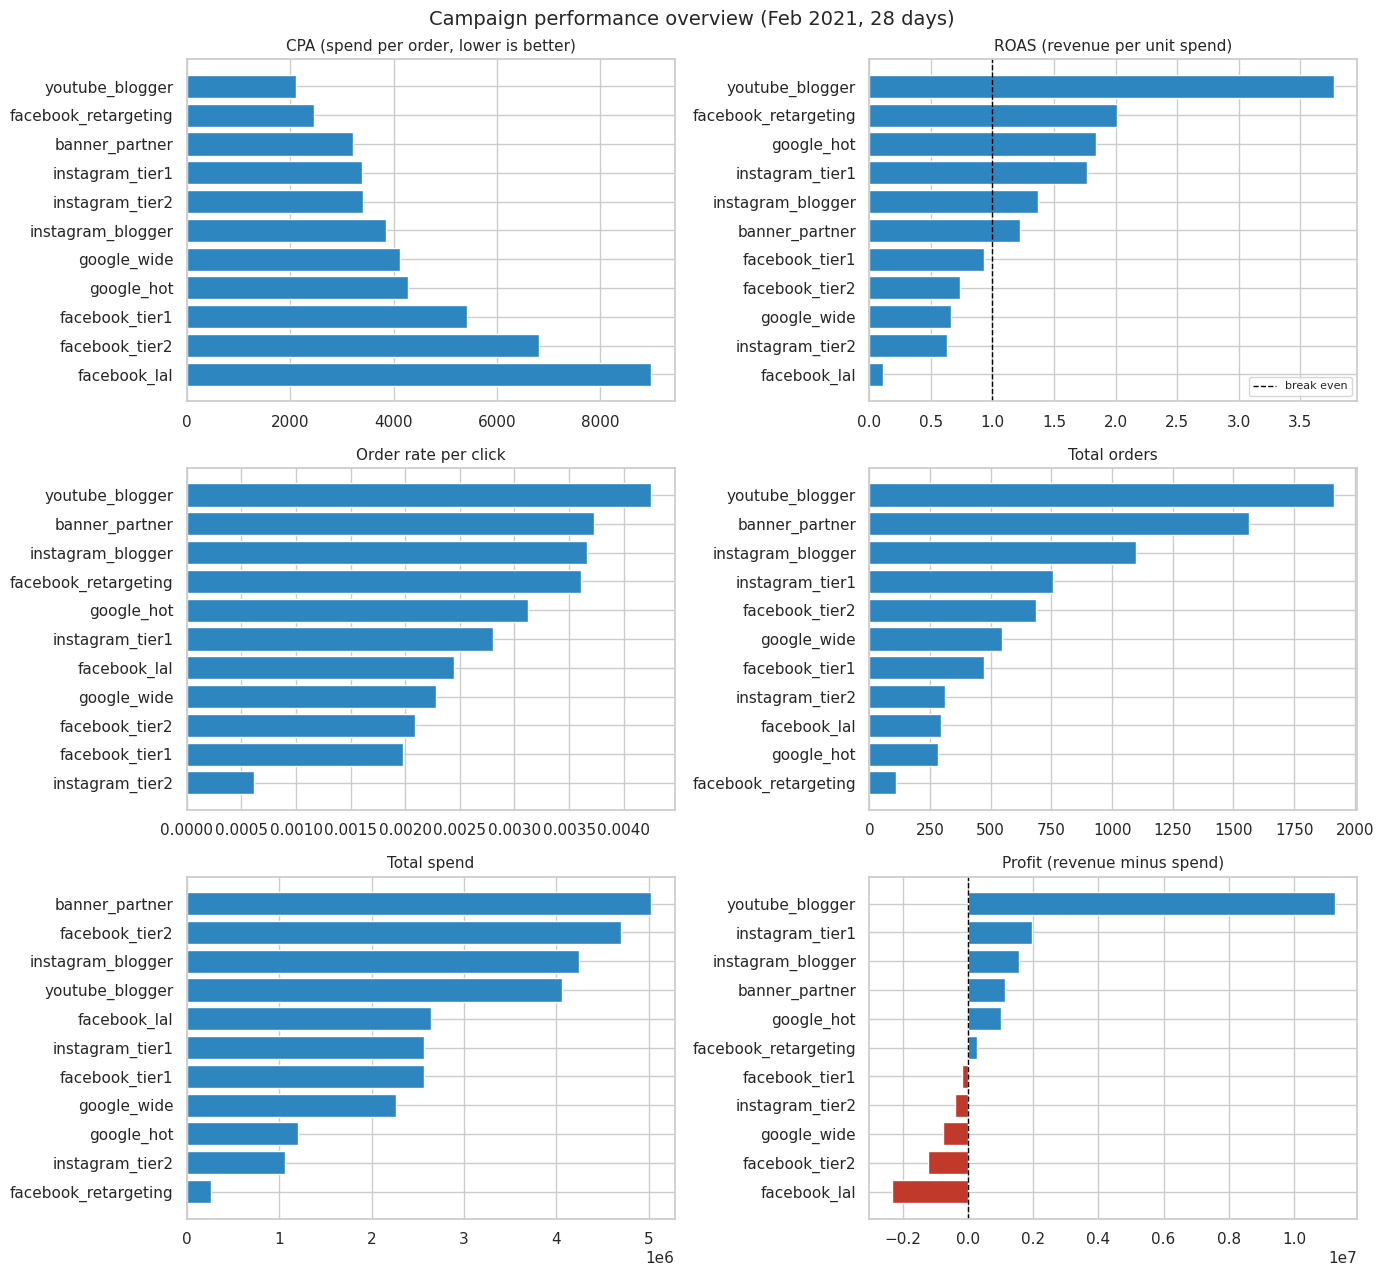

In [6]:
# ---------------------------------------------------------------- figure 1
metrics = [
    ("CPA", "CPA (spend per order, lower is better)", True),
    ("ROAS", "ROAS (revenue per unit spend)", False),
    ("conv_rate", "Order rate per click", False),
    ("orders", "Total orders", False),
    ("spend", "Total spend", False),
    ("profit", "Profit (revenue minus spend)", False),
]
fig, axes = plt.subplots(3, 2, figsize=(14, 13))
for ax, (col, title, ascending) in zip(axes.ravel(), metrics):
    s = camp[col].sort_values(ascending=not ascending)
    colors = ["#c0392b" if v < 0 else "#2e86c1" for v in s.values]
    ax.barh(s.index, s.values, color=colors)
    ax.set_title(title, fontsize=11)
    if col in ("ROAS",):
        ax.axvline(1.0, color="black", ls="--", lw=1, label="break even")
        ax.legend(fontsize=8)
    if col == "profit":
        ax.axvline(0, color="black", ls="--", lw=1)
fig.suptitle("Campaign performance overview (Feb 2021, 28 days)", fontsize=14)
fig.tight_layout()
fig.savefig(FIG / "group_metrics_overview.png", dpi=150)

#### Figure 2

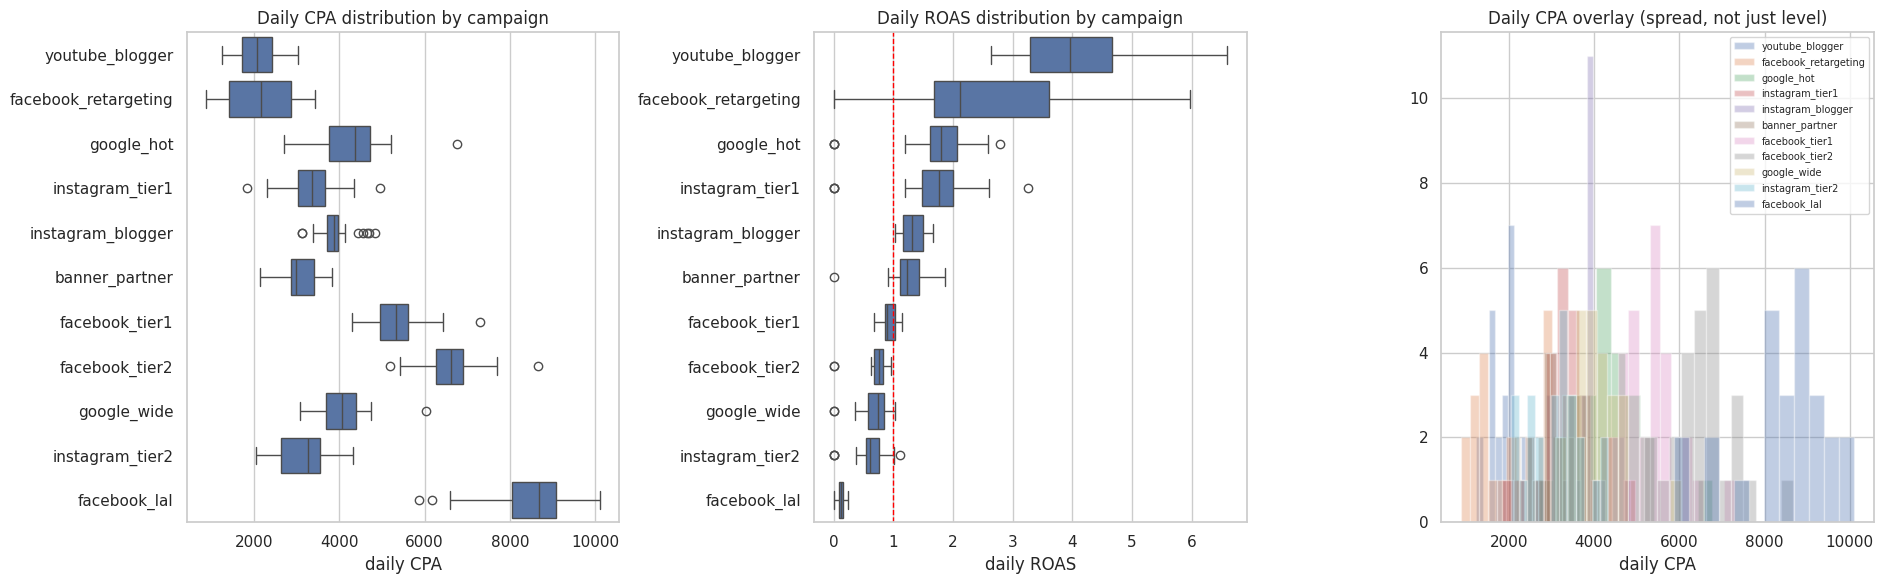

In [7]:
# ---------------------------------------------------------------- figure 2
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
d_cpa = df.dropna(subset=["cpa"])
order = camp.index.tolist()

sns.boxplot(data=d_cpa, y="campaign_name", x="cpa", order=order, ax=axes[0])
axes[0].set_title("Daily CPA distribution by campaign")
axes[0].set_xlabel("daily CPA")
axes[0].set_ylabel("")

sns.boxplot(data=df, y="campaign_name", x="roas", order=order, ax=axes[1])
axes[1].axvline(1.0, color="red", ls="--", lw=1)
axes[1].set_title("Daily ROAS distribution by campaign")
axes[1].set_xlabel("daily ROAS")
axes[1].set_ylabel("")

for c in order:
    sub = d_cpa[d_cpa["campaign_name"] == c]["cpa"]
    axes[2].hist(sub, bins=12, alpha=0.35, label=c)
axes[2].set_title("Daily CPA overlay (spread, not just level)")
axes[2].set_xlabel("daily CPA")
axes[2].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG / "group_distributions.png", dpi=150)

#### Notes

In [8]:
# ---------------------------------------------------------------- notes
print("\n" + "=" * 70)
print("DATA QUALITY FLAGS")
print("=" * 70)
imp = camp["impressions"].sort_values(ascending=False)
print(f"1. Impression volume is extremely skewed. Top campaign "
      f"({imp.index[0]}) has {imp.iloc[0]:,.0f} impressions versus "
      f"{imp.iloc[-1]:,.0f} for the smallest. Its CTR is therefore not "
      f"comparable to click-priced campaigns.")
print(f"2. {zero_order_days} zero-order days are excluded from every CPA test. "
      f"Dropping them biases observed CPA downward for the affected campaigns.")
print("3. Only 28 days per campaign. Every per-campaign test has n = 28 at most.")
print("4. Currency is unlabelled in the source. Treated as generic units and "
      "mapped onto the $500K brief as proportions, not absolute amounts.")
print("\nPart 1 complete.")


DATA QUALITY FLAGS
1. Impression volume is extremely skewed. Top campaign (banner_partner) has 1,068,337,427 impressions versus 976,685 for the smallest. Its CTR is therefore not comparable to click-priced campaigns.
2. 19 zero-order days are excluded from every CPA test. Dropping them biases observed CPA downward for the affected campaigns.
3. Only 28 days per campaign. Every per-campaign test has n = 28 at most.
4. Currency is unlabelled in the source. Treated as generic units and mapped onto the $500K brief as proportions, not absolute amounts.

Part 1 complete.


---

## Parts 2 and 3: pairwise comparisons and multiple comparisons correction

Welch t tests and Fisher's exact test across all 55 campaign pairs, with Cohen's d, then Bonferroni and Benjamini Hochberg correction. Includes an overdispersion diagnostic showing why the pooled Fisher result overstates significance.

In [9]:
ALPHA = 0.05

#### Helpers

In [10]:
# ------------------------------------------------------------------ helpers
def cohens_d(a, b):
    """Pooled-SD Cohen's d, as specified in the lab instructions."""
    pooled = np.sqrt((np.var(a, ddof=1) + np.var(b, ddof=1)) / 2)
    return (np.mean(b) - np.mean(a)) / pooled if pooled > 0 else np.nan

def interpret_d(d):
    ad = abs(d)
    if np.isnan(ad):
        return "undefined"
    if ad < 0.2:
        return "negligible"
    if ad < 0.5:
        return "small"
    if ad < 0.8:
        return "medium"
    return "large"

def pairwise_ttests(frame, group_col, metric):
    """
    Welch t-test on daily values for every unordered pair of groups.

    Deviation from the lab template, stated deliberately: the template calls
    ttest_ind() with its default equal_var=True. Daily CPA variance differs by
    an order of magnitude across these campaigns, so Student's assumption of
    equal variances is violated. Welch is used instead and costs nothing when
    variances happen to be equal.
    """
    d = frame[[group_col, metric]].replace([np.inf, -np.inf], np.nan).dropna()
    d = d[d[metric] > 0] if metric in ("cpa",) else d
    rows = []
    for a, b in combinations(sorted(d[group_col].unique()), 2):
        va = d.loc[d[group_col] == a, metric].values
        vb = d.loc[d[group_col] == b, metric].values
        if len(va) < 3 or len(vb) < 3:
            continue
        t, p = stats.ttest_ind(va, vb, equal_var=False)
        diff = vb.mean() - va.mean()
        d_val = cohens_d(va, vb)
        rows.append(
            dict(
                group_a=a, group_b=b, n_a=len(va), n_b=len(vb),
                mean_a=va.mean(), mean_b=vb.mean(),
                difference=diff,
                pct_difference=100 * diff / va.mean() if va.mean() else np.nan,
                t_stat=t, p_value=p,
                cohens_d=d_val, effect_size=interpret_d(d_val),
                significant_raw=p < ALPHA,
            )
        )
    return pd.DataFrame(rows)

def apply_corrections(res, label):
    """Bonferroni and Benjamini and Hochberg FDR within one family of tests."""
    if res.empty:
        return res
    m = len(res)
    res = res.copy()
    res["alpha_bonferroni"] = ALPHA / m
    res["significant_bonferroni"] = res["p_value"] < ALPHA / m
    res["p_value_fdr"] = false_discovery_control(res["p_value"].values, method="bh")
    res["significant_fdr"] = res["p_value_fdr"] < ALPHA
    print(f"\n[{label}] family size m = {m}, Bonferroni alpha = {ALPHA/m:.6f}")
    print(f"  raw p<0.05        : {int(res.significant_raw.sum())}")
    print(f"  Bonferroni        : {int(res.significant_bonferroni.sum())}")
    print(f"  Benjamini Hochberg: {int(res.significant_fdr.sum())}")
    return res

#### Step 4: t-tests

STEP 4  PAIRWISE t-TESTS ON DAILY METRICS (campaign level)

[CPA campaign] family size m = 55, Bonferroni alpha = 0.000909
  raw p<0.05        : 49
  Bonferroni        : 47
  Benjamini Hochberg: 49



[ROAS campaign] family size m = 55, Bonferroni alpha = 0.000909
  raw p<0.05        : 50
  Bonferroni        : 44
  Benjamini Hochberg: 50

[CPA category] family size m = 6, Bonferroni alpha = 0.008333
  raw p<0.05        : 5
  Bonferroni        : 5
  Benjamini Hochberg: 5

Top 10 CPA comparisons by adjusted significance:
             group_a              group_b    mean_a    mean_b  pct_difference  p_value  p_value_fdr  cohens_d effect_size  significant_fdr
      facebook_tier2      youtube_blogger 6633.0752 2090.7873        -68.4794      0.0          0.0   -7.2512       large             True
        facebook_lal facebook_retargeting 8421.9275 2120.6235        -74.8202      0.0          0.0   -6.6255       large             True
      facebook_tier1      youtube_blogger 5334.6120 2090.7873        -60.8071      0.0          0.0   -5.5816       large             True
facebook_retargeting       facebook_tier2 2120.6235 6633.0752        212.7889      0.0          0.0    6.0034       lar

             group_a              group_b  mean_a  mean_b  pct_difference  p_value  p_value_fdr  cohens_d effect_size  significant_fdr
        facebook_lal       facebook_tier1  0.1191  0.9336        683.8871   0.0000       0.0000    8.5418       large             True
        facebook_lal    instagram_blogger  0.1191  1.3314       1017.8483   0.0000       0.0000    8.7887       large             True
        facebook_lal      youtube_blogger  0.1191  4.0687       3316.1521   0.0000       0.0000    5.4970       large             True
     instagram_tier2      youtube_blogger  0.6005  4.0687        577.5534   0.0000       0.0000    4.6673       large             True
         google_wide      youtube_blogger  0.6742  4.0687        503.5089   0.0000       0.0000    4.5907       large             True
      banner_partner         facebook_lal  1.2423  0.1191        -90.4125   0.0000       0.0000   -4.7271       large             True
      facebook_tier2      youtube_blogger  0.7092  4.06

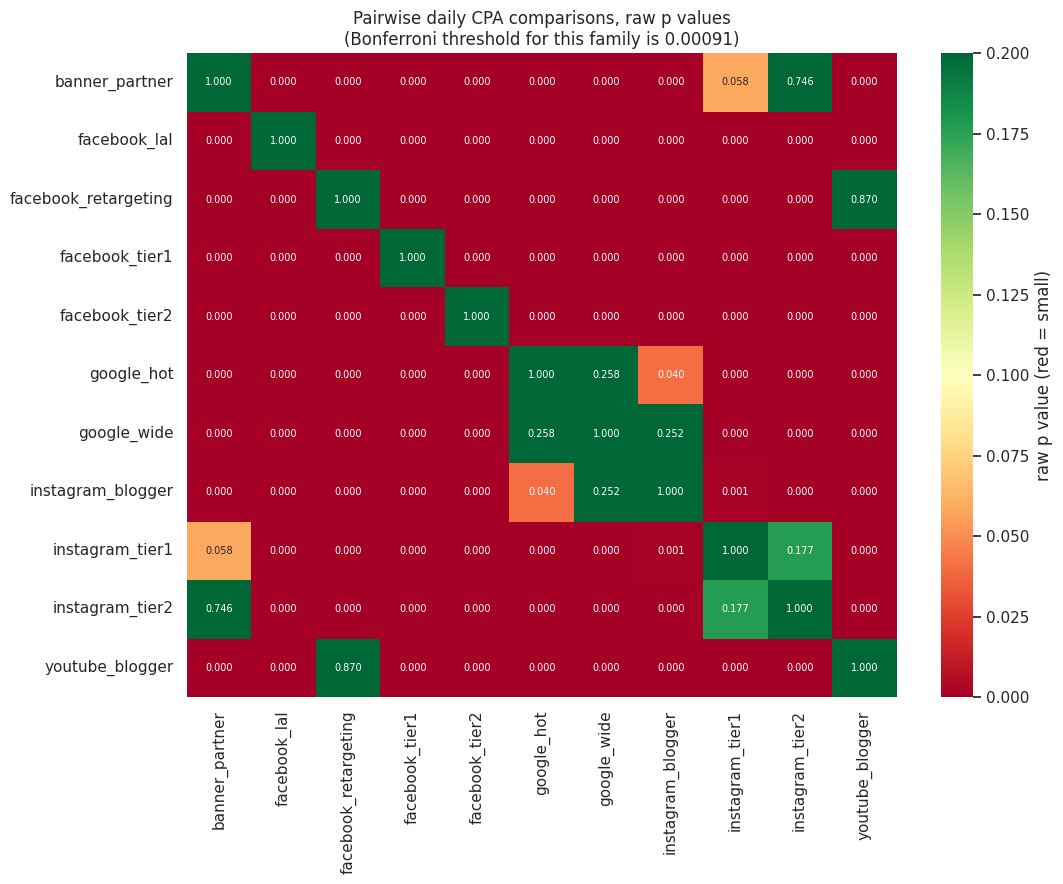

In [11]:
# ------------------------------------------------------------- step 4: t-tests
print("=" * 72)
print("STEP 4  PAIRWISE t-TESTS ON DAILY METRICS (campaign level)")
print("=" * 72)

cpa_res = apply_corrections(pairwise_ttests(df, "campaign_name", "cpa"), "CPA campaign")
roas_res = apply_corrections(pairwise_ttests(df, "campaign_name", "roas"), "ROAS campaign")
cat_res = apply_corrections(pairwise_ttests(df, "category", "cpa"), "CPA category")

print("\nTop 10 CPA comparisons by adjusted significance:")
cols = ["group_a", "group_b", "mean_a", "mean_b", "pct_difference",
        "p_value", "p_value_fdr", "cohens_d", "effect_size", "significant_fdr"]
print(cpa_res.sort_values("p_value")[cols].head(10).round(4).to_string(index=False))

print("\nROAS comparisons surviving FDR:")
sig_roas = roas_res[roas_res.significant_fdr].sort_values("p_value")
print(sig_roas[cols].round(4).to_string(index=False) if len(sig_roas) else "  none")

cpa_res.to_csv(OUT / "ttest_cpa_campaign.csv", index=False)
roas_res.to_csv(OUT / "ttest_roas_campaign.csv", index=False)
cat_res.to_csv(OUT / "ttest_cpa_category.csv", index=False)

# heatmap of raw CPA p-values
groups = sorted(set(cpa_res.group_a) | set(cpa_res.group_b))
mat = pd.DataFrame(np.eye(len(groups)), index=groups, columns=groups)
for _, r in cpa_res.iterrows():
    mat.loc[r.group_a, r.group_b] = r.p_value
    mat.loc[r.group_b, r.group_a] = r.p_value
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(mat, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0, vmax=0.2,
            cbar_kws={"label": "raw p value (red = small)"}, ax=ax,
            annot_kws={"size": 7})
ax.set_title("Pairwise daily CPA comparisons, raw p values\n"
             "(Bonferroni threshold for this family is 0.00091)", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "metric_comparison_heatmap.png", dpi=150)

#### Step 5: Fisher's exact test

In [12]:
# ------------------------------------------------- step 5: Fisher's exact test
print("\n" + "=" * 72)
print("STEP 5  FISHER'S EXACT TEST ON ORDERS PER CLICK (pooled counts)")
print("=" * 72)

agg = df.groupby("campaign_name").agg(orders=("orders", "sum"),
                                      clicks=("clicks", "sum"))
agg["non_orders"] = agg["clicks"] - agg["orders"]
agg["rate"] = agg["orders"] / agg["clicks"]
print(agg.sort_values("rate", ascending=False).round(5).to_string())

rows = []
for a, b in combinations(sorted(agg.index), 2):
    table = [[int(agg.loc[a, "orders"]), int(agg.loc[a, "non_orders"])],
             [int(agg.loc[b, "orders"]), int(agg.loc[b, "non_orders"])]]
    odds, p = fisher_exact(table, alternative="two-sided")
    ra, rb = agg.loc[a, "rate"], agg.loc[b, "rate"]
    rows.append(dict(group_a=a, group_b=b,
                     orders_a=table[0][0], clicks_a=int(agg.loc[a, "clicks"]),
                     orders_b=table[1][0], clicks_b=int(agg.loc[b, "clicks"]),
                     rate_a=ra, rate_b=rb, difference=rb - ra,
                     pct_difference=100 * (rb - ra) / ra if ra else np.nan,
                     odds_ratio=odds, p_value=p, significant_raw=p < ALPHA))
fisher_res = apply_corrections(pd.DataFrame(rows), "Fisher order rate campaign")
fisher_res.to_csv(OUT / "fisher_convrate_campaign.csv", index=False)


STEP 5  FISHER'S EXACT TEST ON ORDERS PER CLICK (pooled counts)
                      orders  clicks  non_orders     rate
campaign_name                                            
youtube_blogger         1914  450014      448100  0.00425
banner_partner          1566  420003      418437  0.00373
instagram_blogger       1100  299959      298859  0.00367
facebook_retargeting     108   29954       29846  0.00361
google_hot               281   90048       89767  0.00312
instagram_tier1          758  269961      269203  0.00281
facebook_lal             294  120012      119718  0.00245
google_wide              547  240006      239459  0.00228
facebook_tier2           688  329973      329285  0.00209
facebook_tier1           474  239997      239523  0.00198
instagram_tier2          313  509992      509679  0.00061

[Fisher order rate campaign] family size m = 55, Bonferroni alpha = 0.000909
  raw p<0.05        : 46
  Bonferroni        : 38
  Benjamini Hochberg: 45


#### Overdispersion diagnostic (the reason not to trust the line above)


------------------------------------------------------------------------
OVERDISPERSION CHECK: pooled Fisher vs a test that respects daily variation
------------------------------------------------------------------------
Fisher on pooled clicks assumes every click is an independent Bernoulli
draw with a fixed per-campaign rate. Daily order rates are overdispersed,
so pooling inflates the effective sample size and shrinks p values.
Below: the same pairs tested on 28 daily order rates instead.

pairs significant under pooled Fisher : 46 of 55
pairs significant on daily rates      : 33 of 55
pairs Fisher calls significant that daily-rate testing does not: 13


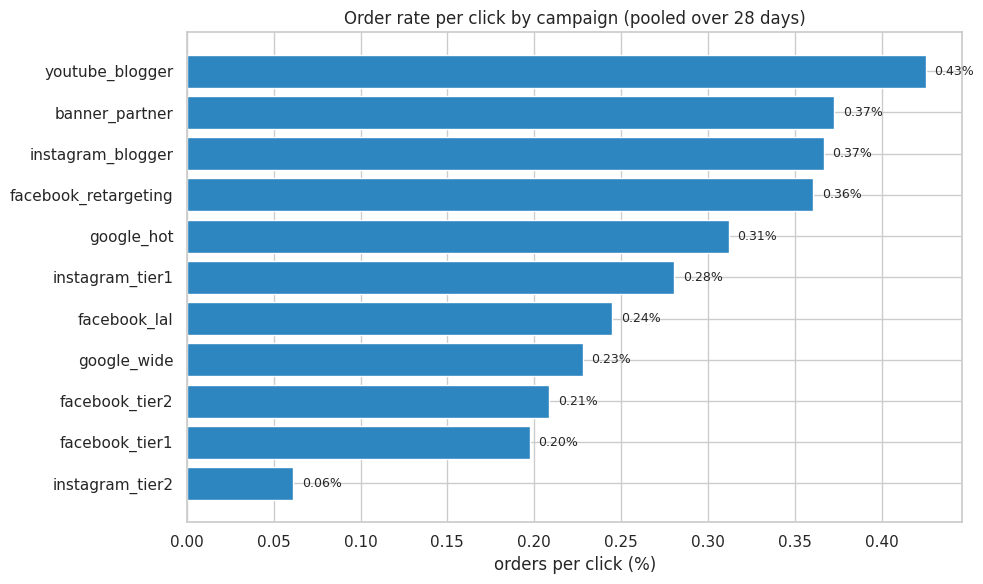

In [13]:
# ---- overdispersion diagnostic (the reason not to trust the line above)
print("\n" + "-" * 72)
print("OVERDISPERSION CHECK: pooled Fisher vs a test that respects daily variation")
print("-" * 72)
print("Fisher on pooled clicks assumes every click is an independent Bernoulli\n"
      "draw with a fixed per-campaign rate. Daily order rates are overdispersed,\n"
      "so pooling inflates the effective sample size and shrinks p values.\n"
      "Below: the same pairs tested on 28 daily order rates instead.")

daily_rate_res = pairwise_ttests(df, "campaign_name", "conv_rate")
merged = fisher_res.merge(
    daily_rate_res[["group_a", "group_b", "p_value", "cohens_d"]],
    on=["group_a", "group_b"], suffixes=("_fisher", "_daily"))
merged["fisher_sig_raw"] = merged["p_value_fisher"] < ALPHA
merged["daily_sig_raw"] = merged["p_value_daily"] < ALPHA
flips = merged[merged.fisher_sig_raw & ~merged.daily_sig_raw]
print(f"\npairs significant under pooled Fisher : {int(merged.fisher_sig_raw.sum())} of {len(merged)}")
print(f"pairs significant on daily rates      : {int(merged.daily_sig_raw.sum())} of {len(merged)}")
print(f"pairs Fisher calls significant that daily-rate testing does not: {len(flips)}")
merged.to_csv(OUT / "overdispersion_check.csv", index=False)

# rate comparison chart
fig, ax = plt.subplots(figsize=(10, 6))
s = agg["rate"].sort_values()
ax.barh(s.index, s.values * 100, color="#2e86c1")
for i, v in enumerate(s.values * 100):
    ax.text(v + 0.005, i, f"{v:.2f}%", va="center", fontsize=9)
ax.set_xlabel("orders per click (%)")
ax.set_title("Order rate per click by campaign (pooled over 28 days)")
fig.tight_layout()
fig.savefig(FIG / "rate_comparison.png", dpi=150)

#### Step 6: correction comparison


STEP 6  MULTIPLE COMPARISONS SUMMARY
total tests run across families: 165
expected false positives at alpha=0.05 with no correction: 8.2

                     family  n_tests  uncorrected  bonferroni  fdr_bh
        CPA (t-test, daily)       55           49          47      49
       ROAS (t-test, daily)       55           50          44      50
Order rate (Fisher, pooled)       55           46          38      45

Parts 2 and 3 complete.


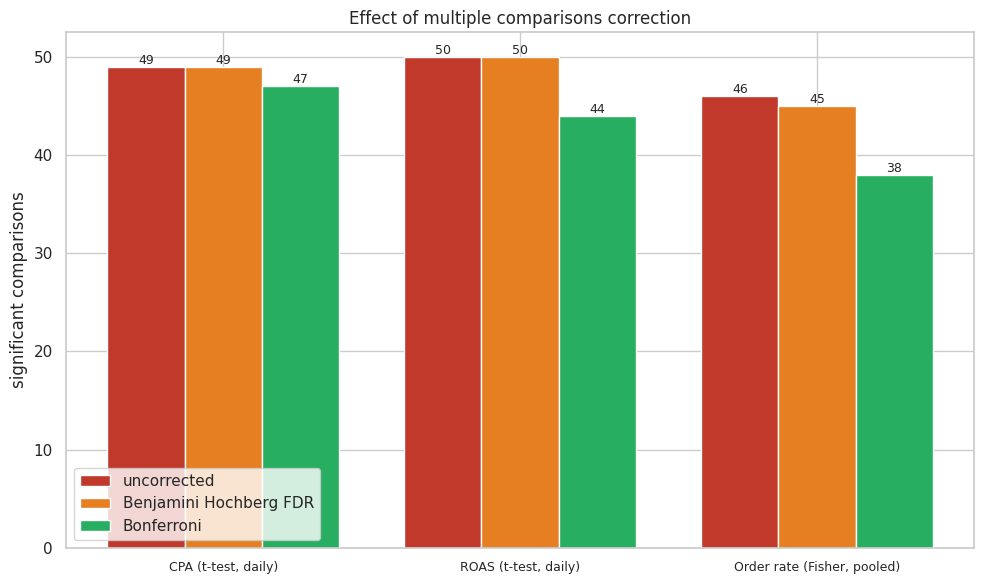

In [14]:
# --------------------------------------------- step 6: correction comparison
print("\n" + "=" * 72)
print("STEP 6  MULTIPLE COMPARISONS SUMMARY")
print("=" * 72)
total = len(cpa_res) + len(fisher_res) + len(roas_res)
print(f"total tests run across families: {total}")
print(f"expected false positives at alpha=0.05 with no correction: {total * ALPHA:.1f}")

correction_summary = pd.DataFrame([
    dict(family="CPA (t-test, daily)", n_tests=len(cpa_res),
         uncorrected=int(cpa_res.significant_raw.sum()),
         bonferroni=int(cpa_res.significant_bonferroni.sum()),
         fdr_bh=int(cpa_res.significant_fdr.sum())),
    dict(family="ROAS (t-test, daily)", n_tests=len(roas_res),
         uncorrected=int(roas_res.significant_raw.sum()),
         bonferroni=int(roas_res.significant_bonferroni.sum()),
         fdr_bh=int(roas_res.significant_fdr.sum())),
    dict(family="Order rate (Fisher, pooled)", n_tests=len(fisher_res),
         uncorrected=int(fisher_res.significant_raw.sum()),
         bonferroni=int(fisher_res.significant_bonferroni.sum()),
         fdr_bh=int(fisher_res.significant_fdr.sum())),
])
print("\n" + correction_summary.to_string(index=False))
correction_summary.to_csv(OUT / "correction_summary.csv", index=False)

x = np.arange(len(correction_summary))
w = 0.26
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - w, correction_summary.uncorrected, w, label="uncorrected", color="#c0392b")
ax.bar(x, correction_summary.fdr_bh, w, label="Benjamini Hochberg FDR", color="#e67e22")
ax.bar(x + w, correction_summary.bonferroni, w, label="Bonferroni", color="#27ae60")
ax.set_xticks(x)
ax.set_xticklabels(correction_summary.family, fontsize=9)
ax.set_ylabel("significant comparisons")
ax.set_title("Effect of multiple comparisons correction")
ax.legend()
for i, r in correction_summary.iterrows():
    ax.text(i - w, r.uncorrected + 0.3, str(r.uncorrected), ha="center", fontsize=9)
    ax.text(i, r.fdr_bh + 0.3, str(r.fdr_bh), ha="center", fontsize=9)
    ax.text(i + w, r.bonferroni + 0.3, str(r.bonferroni), ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "correction_comparison.png", dpi=150)

print("\nParts 2 and 3 complete.")

---

## Part 4: power analysis and sample size planning

Simulated power using the coefficient of variation measured from the data rather than an assumed value, plus a sensitivity check on that assumption.

In [15]:
rng = np.random.default_rng(42)
ALPHA = 0.05
TARGET_POWER = 0.80
N_SIM = 1000
CURRENT_DAYS = 28  # this dataset, not the 90 the template assumes

cpa = df.dropna(subset=["cpa"])

#### Measured variability

In [16]:
# ------------------------------------------------- measured variability
per_campaign = cpa.groupby("campaign_name")["cpa"].agg(["count", "mean", "std"])
per_campaign["cv"] = per_campaign["std"] / per_campaign["mean"]
OBSERVED_CV = float(per_campaign["cv"].median())
BASE_CPA = float(per_campaign["mean"].median())

print("=" * 72)
print("OBSERVED DAILY CPA VARIABILITY (input to the simulation)")
print("=" * 72)
print(per_campaign.round(3).to_string())
print(f"\nmedian coefficient of variation: {OBSERVED_CV:.3f}")
print(f"median campaign CPA (simulation baseline): {BASE_CPA:,.0f}")
print(f"template assumption was 0.150; measured value is used instead")
print(f"note: usable days per campaign range "
      f"{int(per_campaign['count'].min())} to {int(per_campaign['count'].max())} "
      f"because zero-order days drop out")

def empirical_power_cpa(true_diff_pct, base_cpa=BASE_CPA, n_days=CURRENT_DAYS,
                        cv=OBSERVED_CV, n_sim=N_SIM, alpha=ALPHA):
    """Proportion of simulated experiments that reject H0 at alpha."""
    sd = base_cpa * cv
    mean_b = base_cpa * (1 + true_diff_pct)
    a = np.clip(rng.normal(base_cpa, sd, (n_sim, n_days)), base_cpa * 0.5, None)
    b = np.clip(rng.normal(mean_b, sd, (n_sim, n_days)), mean_b * 0.5, None)
    _, p = stats.ttest_ind(a, b, axis=1, equal_var=False)
    return float((p < alpha).mean())

OBSERVED DAILY CPA VARIABILITY (input to the simulation)
                      count      mean       std     cv
campaign_name                                         
banner_partner           27  3071.595   424.736  0.138
facebook_lal             26  8421.927  1099.859  0.131
facebook_retargeting     25  2120.623   774.198  0.365
facebook_tier1           28  5334.612   649.053  0.122
facebook_tier2           26  6633.075   728.392  0.110
google_hot               25  4295.268   831.546  0.194
google_wide              26  4063.898   584.254  0.144
instagram_blogger        28  3900.535   432.762  0.111
instagram_tier1          25  3368.873   644.220  0.191
instagram_tier2          25  3120.853   635.517  0.204
youtube_blogger          28  2090.787   504.224  0.241

median coefficient of variation: 0.144
median campaign CPA (simulation baseline): 3,901
template assumption was 0.150; measured value is used instead
note: usable days per campaign range 25 to 28 because zero-order days drop ou

#### Power grid

In [17]:
# ------------------------------------------------------------- power grid
effects = [0.05, 0.10, 0.15, 0.20]
sample_sizes = [14, 28, 60, 90, 120, 180]
rows = []
for e in effects:
    for n in sample_sizes:
        rows.append(dict(effect_size_pct=int(e * 100), n_days=n,
                         power=empirical_power_cpa(e, n_days=n)))
grid = pd.DataFrame(rows)
grid.to_csv(OUT / "power_grid.csv", index=False)

print("\n" + "=" * 72)
print("POWER TO DETECT A CPA DIFFERENCE (simulated, measured variability)")
print("=" * 72)
print(grid.pivot(index="n_days", columns="effect_size_pct", values="power")
      .round(3).to_string())

# sensitivity: what if variability were higher than the median campaign
print("\nsensitivity of power at 28 days to the assumed CV:")
for cv in [0.11, OBSERVED_CV, 0.20, 0.30]:
    p10 = empirical_power_cpa(0.10, cv=cv, n_days=CURRENT_DAYS)
    p20 = empirical_power_cpa(0.20, cv=cv, n_days=CURRENT_DAYS)
    print(f"  CV {cv:.3f}: power at 10% diff = {p10:.2f}, at 20% diff = {p20:.2f}")


POWER TO DETECT A CPA DIFFERENCE (simulated, measured variability)
effect_size_pct     5      10     15     20
n_days                                     
14               0.151  0.408  0.766  0.945
28               0.251  0.729  0.968  0.999
60               0.508  0.973  1.000  1.000
90               0.632  0.995  1.000  1.000
120              0.762  1.000  1.000  1.000
180              0.905  1.000  1.000  1.000

sensitivity of power at 28 days to the assumed CV:
  CV 0.110: power at 10% diff = 0.91, at 20% diff = 1.00
  CV 0.144: power at 10% diff = 0.73, at 20% diff = 1.00
  CV 0.200: power at 10% diff = 0.47, at 20% diff = 0.96
  CV 0.300: power at 10% diff = 0.25, at 20% diff = 0.68


#### Minimum sample size

In [18]:
# ------------------------------------------------------- minimum sample size
print("\n" + "=" * 72)
print(f"MINIMUM DAYS FOR {TARGET_POWER:.0%} POWER")
print("=" * 72)
mde_rows = []
for e in effects:
    need = None
    for n in range(5, 401, 5):
        if empirical_power_cpa(e, n_days=n, n_sim=400) >= TARGET_POWER:
            need = n
            break
    mde_rows.append(dict(effect_size_pct=int(e * 100), min_days_for_80pct=need,
                         current_days=CURRENT_DAYS,
                         status="sufficient" if need and need <= CURRENT_DAYS
                         else "insufficient"))
mde = pd.DataFrame(mde_rows)
mde.to_csv(OUT / "mde_table.csv", index=False)
print(mde.to_string(index=False))

# smallest detectable difference at 28 days
detectable = None
for e in np.arange(0.02, 0.51, 0.01):
    if empirical_power_cpa(float(e), n_days=CURRENT_DAYS, n_sim=600) >= TARGET_POWER:
        detectable = e
        break
print(f"\nsmallest CPA difference detectable at 80% power with "
      f"{CURRENT_DAYS} days: about {detectable:.0%}")


MINIMUM DAYS FOR 80% POWER


 effect_size_pct  min_days_for_80pct  current_days       status
               5                 135            28 insufficient
              10                  35            28 insufficient
              15                  20            28   sufficient
              20                  10            28   sufficient

smallest CPA difference detectable at 80% power with 28 days: about 11%


#### Power curves

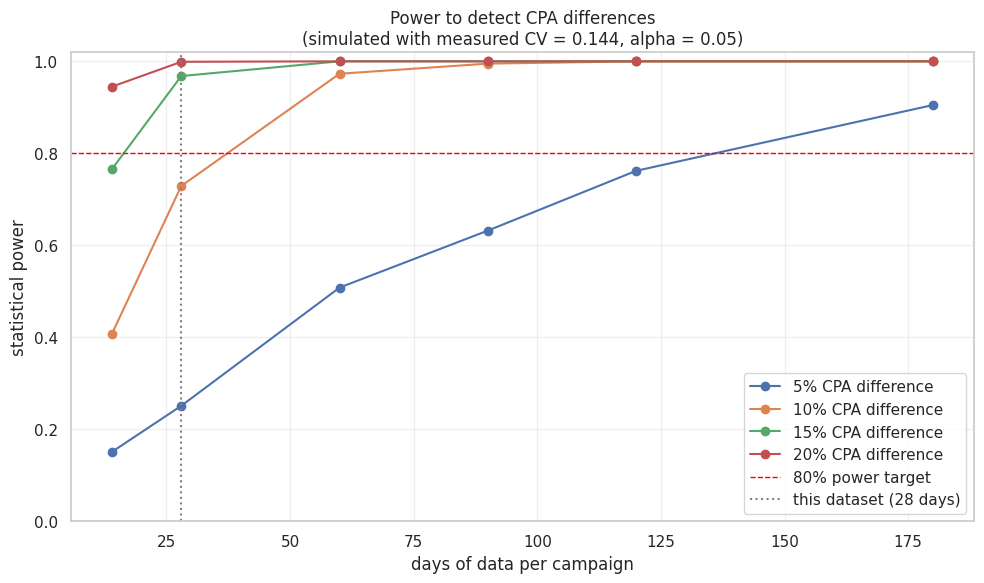

In [19]:
# ------------------------------------------------------------- power curves
fig, ax = plt.subplots(figsize=(10, 6))
for e in effects:
    sub = grid[grid.effect_size_pct == int(e * 100)]
    ax.plot(sub.n_days, sub.power, marker="o", label=f"{int(e*100)}% CPA difference")
ax.axhline(0.80, color="red", ls="--", lw=1, label="80% power target")
ax.axvline(CURRENT_DAYS, color="grey", ls=":", lw=1.5,
           label=f"this dataset ({CURRENT_DAYS} days)")
ax.set_xlabel("days of data per campaign")
ax.set_ylabel("statistical power")
ax.set_title(f"Power to detect CPA differences\n"
             f"(simulated with measured CV = {OBSERVED_CV:.3f}, alpha = 0.05)")
ax.set_ylim(0, 1.02)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "power_analysis_cpa.png", dpi=150)

#### Adequacy for the pairs we called significant

In [20]:
# --------------------------------- adequacy for the pairs we called significant
print("\n" + "=" * 72)
print("ADEQUACY CHECK ON PAIRS THAT SURVIVED FDR CORRECTION")
print("=" * 72)
res = cpa_res.copy()          # in-kernel, no re-read needed
sig = res[res.significant_fdr].copy()
rows = []
for _, r in sig.iterrows():
    base = min(r.mean_a, r.mean_b)
    obs_pct = abs(r.mean_b - r.mean_a) / base
    pw = empirical_power_cpa(float(obs_pct), base_cpa=base,
                             n_days=CURRENT_DAYS, n_sim=500)
    need = None
    if pw < TARGET_POWER:
        for n in range(5, 401, 5):
            if empirical_power_cpa(float(obs_pct), base_cpa=base,
                                   n_days=n, n_sim=300) >= TARGET_POWER:
                need = n
                break
    rows.append(dict(group_a=r.group_a, group_b=r.group_b,
                     observed_pct_diff=round(100 * obs_pct, 1),
                     cohens_d=round(r.cohens_d, 2),
                     power_at_28_days=round(pw, 3),
                     days_needed_for_80pct=need))
adequacy = pd.DataFrame(rows).sort_values("power_at_28_days")
adequacy.to_csv(OUT / "power_adequacy_significant_pairs.csv", index=False)
print(f"{len(sig)} pairs survived FDR. Underpowered pairs shown first:")
print(adequacy.head(15).to_string(index=False))
n_under = int((adequacy.power_at_28_days < TARGET_POWER).sum())
print(f"\npairs with power below {TARGET_POWER:.0%} despite being 'significant': {n_under}")
print("\nPart 4 complete.")


ADEQUACY CHECK ON PAIRS THAT SURVIVED FDR CORRECTION
49 pairs survived FDR. Underpowered pairs shown first:
          group_a              group_b  observed_pct_diff  cohens_d  power_at_28_days  days_needed_for_80pct
       google_hot    instagram_blogger               10.1     -0.60             0.722                   35.0
instagram_blogger      instagram_tier1               15.8     -0.97             0.978                    NaN
   banner_partner         facebook_lal              174.2      6.42             1.000                    NaN
   banner_partner facebook_retargeting               44.8     -1.52             1.000                    NaN
   banner_partner           google_hot               39.8      1.85             1.000                    NaN
   banner_partner          google_wide               32.3      1.94             1.000                    NaN
   banner_partner       facebook_tier1               73.7      4.13             1.000                    NaN
   banner_partner  

---

## Part 5: confidence intervals, ranking and budget allocation

Bootstrap confidence intervals on daily means, a composite rank score, and two allocations of the 500K monthly budget.

In [21]:
rng = np.random.default_rng(7)
BUDGET = 500_000
MIN_SHARE, MAX_SHARE = 0.03, 0.25

summary = camp.copy()         # built in Part 1

#### Bootstrap CI

BOOTSTRAP 95% CONFIDENCE INTERVALS ON DAILY MEANS (2000 resamples)
            campaign  n_days  mean_daily_cpa  cpa_ci_low  cpa_ci_high  ci_width_pct  mean_daily_roas  roas_ci_low  roas_ci_high
     youtube_blogger      28        2090.787    1915.367     2283.944        17.629            4.069        3.697         4.451
facebook_retargeting      25        2120.623    1835.704     2429.162        27.985            2.450        1.929         2.973
      banner_partner      27        3071.595    2905.082     3229.156        10.551            1.242        1.114         1.354
     instagram_tier2      25        3120.853    2876.662     3364.908        15.645            0.600        0.495         0.697
     instagram_tier1      25        3368.873    3111.258     3625.248        15.257            1.646        1.381         1.893
   instagram_blogger      28        3900.535    3747.158     4047.816         7.708            1.331        1.264         1.403
         google_wide      26        4

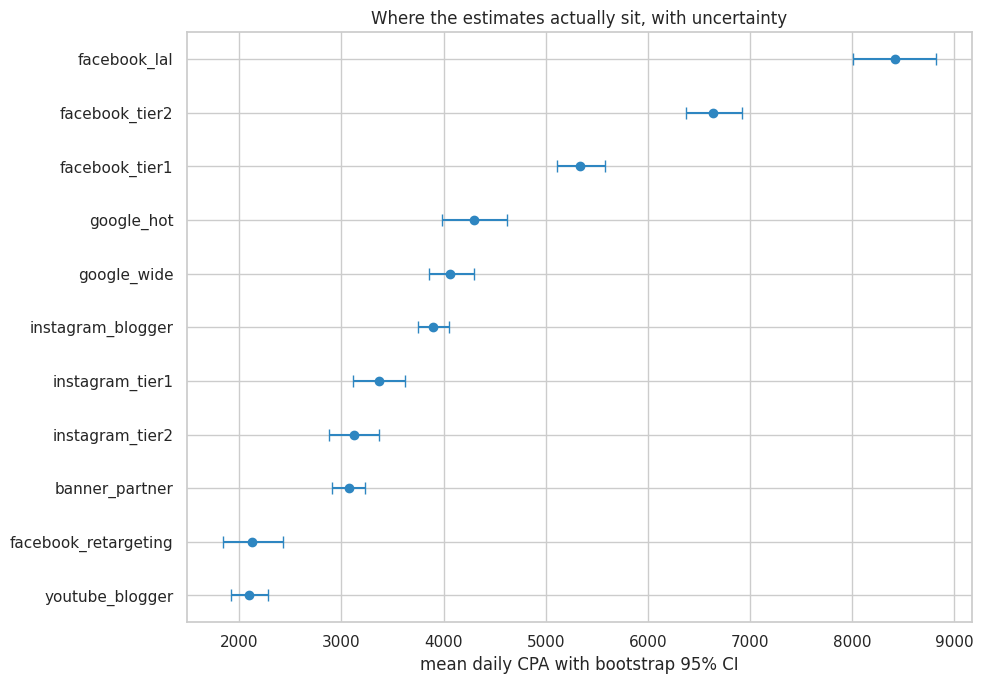

In [22]:
# ------------------------------------------------------------ bootstrap CI
def bootstrap_ci(data, n_bootstrap=2000, ci_level=0.95):
    data = np.asarray(data, dtype=float)
    data = data[np.isfinite(data)]
    if len(data) < 3:
        return np.nan, np.nan
    means = rng.choice(data, size=(n_bootstrap, len(data)), replace=True).mean(axis=1)
    lo = (1 - ci_level) / 2 * 100
    return float(np.percentile(means, lo)), float(np.percentile(means, 100 - lo))

rows = []
for camp_name, sub in df.groupby("campaign_name"):
    cpa_vals = sub["cpa"].dropna()
    roas_vals = sub["roas"].dropna()
    lo_c, hi_c = bootstrap_ci(cpa_vals)
    lo_r, hi_r = bootstrap_ci(roas_vals)
    rows.append(dict(campaign=camp_name, n_days=len(cpa_vals),
                     mean_daily_cpa=cpa_vals.mean(),
                     cpa_ci_low=lo_c, cpa_ci_high=hi_c,
                     ci_width_pct=100 * (hi_c - lo_c) / cpa_vals.mean(),
                     mean_daily_roas=roas_vals.mean(),
                     roas_ci_low=lo_r, roas_ci_high=hi_r))
ci = pd.DataFrame(rows).sort_values("mean_daily_cpa")
ci.round(3).to_csv(OUT / "bootstrap_ci_cpa.csv", index=False)

print("=" * 78)
print("BOOTSTRAP 95% CONFIDENCE INTERVALS ON DAILY MEANS (2000 resamples)")
print("=" * 78)
print(ci.round(3).to_string(index=False))

overlap = []
c = ci.set_index("campaign")
for a in c.index:
    for b in c.index:
        if a < b and not (c.loc[a, "cpa_ci_high"] < c.loc[b, "cpa_ci_low"]
                          or c.loc[b, "cpa_ci_high"] < c.loc[a, "cpa_ci_low"]):
            overlap.append((a, b))
print(f"\ncampaign pairs whose CPA confidence intervals overlap: {len(overlap)} of 55")

fig, ax = plt.subplots(figsize=(10, 7))
o = ci.sort_values("mean_daily_cpa")
ax.errorbar(o.mean_daily_cpa, range(len(o)),
            xerr=[o.mean_daily_cpa - o.cpa_ci_low, o.cpa_ci_high - o.mean_daily_cpa],
            fmt="o", capsize=4, color="#2e86c1")
ax.set_yticks(range(len(o)))
ax.set_yticklabels(o.campaign)
ax.set_xlabel("mean daily CPA with bootstrap 95% CI")
ax.set_title("Where the estimates actually sit, with uncertainty")
fig.tight_layout()
fig.savefig(FIG / "cpa_confidence_intervals.png", dpi=150)

#### Composite ranking

In [23]:
# --------------------------------------------------------- composite ranking
r = summary.copy()
r["rank_cpa"] = r["CPA"].rank(ascending=True)      # lower CPA is better
r["rank_roas"] = r["ROAS"].rank(ascending=False)   # higher ROAS is better
r["composite_rank"] = 0.5 * r["rank_cpa"] + 0.5 * r["rank_roas"]
r["score"] = len(r) + 1 - r["composite_rank"]      # higher score is better
r = r.sort_values("score", ascending=False)
r[["CPA", "ROAS", "profit", "rank_cpa", "rank_roas", "composite_rank", "score"]] \
    .round(3).to_csv(OUT / "composite_ranking.csv")

print("\n" + "=" * 78)
print("COMPOSITE RANKING (50% CPA rank, 50% ROAS rank)")
print("=" * 78)
print(r[["CPA", "ROAS", "profit", "composite_rank", "score"]].round(2).to_string())


COMPOSITE RANKING (50% CPA rank, 50% ROAS rank)
                          CPA  ROAS       profit  composite_rank  score
campaign_name                                                          
youtube_blogger       2120.13  3.77  11253496.49             1.0   11.0
facebook_retargeting  2467.28  2.01    270452.78             2.0   10.0
instagram_tier1       3384.27  1.77   1978846.75             4.0    8.0
banner_partner        3209.88  1.22   1126285.24             4.5    7.5
google_hot            4270.46  1.84   1005748.24             5.5    6.5
instagram_blogger     3861.24  1.37   1561086.43             5.5    6.5
instagram_tier2       3406.24  0.63   -395693.75             7.5    4.5
facebook_tier1        5410.96  0.93   -168381.48             8.0    4.0
google_wide           4132.36  0.66   -761083.31             8.0    4.0
facebook_tier2        6822.49  0.74  -1230564.97             9.0    3.0
facebook_lal          8986.19  0.11  -2341706.24            11.0    1.0


#### Allocation

In [24]:
# ------------------------------------------------------------- allocation
# Two allocations are produced deliberately.
#
# A. Template allocation: budget proportional to composite score, capped.
#    Ranks discard magnitude, so a campaign returning 0.11 on spend gets a
#    floor allocation only because it is not last on every metric.
#
# B. Profitability screen: campaigns below break-even ROAS get a test budget
#    only, and the released spend goes to campaigns with proven positive
#    return, still capped to avoid assuming linear scaling.
raw = r["score"] / r["score"].sum()
capped = raw.clip(MIN_SHARE, MAX_SHARE)
alloc_a = capped / capped.sum()

profitable = r["ROAS"] >= 1.0
share_b = pd.Series(0.0, index=r.index)
share_b[~profitable] = MIN_SHARE
remaining = 1 - share_b.sum()
w = r.loc[profitable, "score"] / r.loc[profitable, "score"].sum()
share_b[profitable] = (w * remaining).clip(upper=MAX_SHARE)
share_b = share_b / share_b.sum()

alloc = pd.DataFrame({
    "current_share": (r["spend"] / r["spend"].sum()),
    "alloc_A_rank_proportional": alloc_a,
    "alloc_B_profit_screened": share_b,
    "ROAS": r["ROAS"], "CPA": r["CPA"],
})
alloc["A_budget"] = (alloc["alloc_A_rank_proportional"] * BUDGET).round(0)
alloc["B_budget"] = (alloc["alloc_B_profit_screened"] * BUDGET).round(0)
alloc["change_vs_current_B_pp"] = 100 * (alloc["alloc_B_profit_screened"]
                                         - alloc["current_share"])
alloc.round(4).to_csv(OUT / "budget_allocation.csv")

print("\n" + "=" * 78)
print(f"BUDGET ALLOCATION OPTIONS ON ${BUDGET:,}/month")
print("=" * 78)
show = alloc.copy()
for col in ["current_share", "alloc_A_rank_proportional", "alloc_B_profit_screened"]:
    show[col] = (100 * show[col]).round(1)
print(show[["ROAS", "current_share", "alloc_A_rank_proportional",
            "alloc_B_profit_screened", "B_budget", "change_vs_current_B_pp"]]
      .round(1).to_string())

print(f"\nspend currently going to campaigns with ROAS below 1.0: "
      f"{100 * alloc.loc[alloc.ROAS < 1, 'current_share'].sum():.1f}% of budget")
print("\nPart 5 complete.")


BUDGET ALLOCATION OPTIONS ON $500,000/month
                      ROAS  current_share  alloc_A_rank_proportional  alloc_B_profit_screened  B_budget  change_vs_current_B_pp
campaign_name                                                                                                                  
youtube_blogger        3.8           13.3                       16.4                     18.9   94444.0                     5.6
facebook_retargeting   2.0            0.9                       14.9                     17.2   85859.0                    16.3
instagram_tier1        1.8            8.4                       11.9                     13.7   68687.0                     5.4
banner_partner         1.2           16.4                       11.2                     12.9   64394.0                    -3.6
google_hot             1.8            3.9                        9.7                     11.2   55808.0                     7.2
instagram_blogger      1.4           13.9                  